<a href="https://colab.research.google.com/github/Amerta1090/Pull-Up-Counter-Edited-Video/blob/main/Pull_Up_Counter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🏋️‍♂️ AI Pull-Up Counter & Analyzer (Social Media Ready)
Notebook ini digunakan untuk mendeteksi, menganalisis, dan menghitung repetisi olahraga *pull-up* secara otomatis menggunakan model estimasi pose tubuh **YOLO11 Pose**.

Hasil video akhir akan memiliki informasi visual sudut siku, status gerakan (`UP`/`DOWN`), dan total repetisi yang aman dari pemotongan antarmuka/UI media sosial (seperti Instagram Reels atau TikTok).

## 1. Instalasi & Import Dependensi

In [1]:
#@title Install Library Utama
!pip -q install ultralytics opencv-python-headless matplotlib

In [2]:
#@title Import Library
import cv2
import numpy as np
import math
import os
from collections import deque
import matplotlib.pyplot as plt

from ultralytics import YOLO
from google.colab import files
from IPython.display import Video, display

## 2. Pengunggahan Video & Konfigurasi

In [3]:
#@title Unggah Video Olahraga Anda
uploaded = files.upload()
video_path = next(iter(uploaded))

# Membaca informasi dasar video
cap = cv2.VideoCapture(video_path)
fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
duration = frame_count / fps
cap.release()

print("\n--- INFORMASI VIDEO ---")
print(f"Nama File  : {video_path}")
print(f"Resolusi   : {width}x{height}")
print(f"FPS        : {fps:.2f}")
print(f"Durasi     : {duration:.2f} detik")

Saving 15859716-uhd_3840_2160_30fps.mp4 to 15859716-uhd_3840_2160_30fps (1).mp4

--- INFORMASI VIDEO ---
Nama File  : 15859716-uhd_3840_2160_30fps (1).mp4
Resolusi   : 3840x2160
FPS        : 30.00
Durasi     : 9.43 detik


In [4]:
#@title Pengaturan Ambang Batas (Tuning Parameter)
# Konfigurasi YOLO
CONF_THRESHOLD = 0.40   # Sensitivitas deteksi manusia
KEYPOINT_CONF = 0.35    # Sensitivitas deteksi sendi tubuh (keypoints)

# Ambang Batas Sudut Siku (Tuned)
TUNED_UP_ANGLE = 105    # Batas maksimal menekuk untuk dinyatakan posisi UP (naik)
TUNED_DOWN_ANGLE = 130  # Batas minimal lurus untuk dinyatakan posisi DOWN (turun)

# Smoothing (Menghindari jitter/gerakan patah-patah)
SMOOTHING_WINDOW = 5

# Output File
OUTPUT_FINAL_PATH = "pullup_sosmed_revised.mp4"

## 3. Fungsi Pembantu & Load Model

In [5]:
#@title Definisikan Fungsi Kalkulasi Matematika
def calculate_angle(a, b, c):
    """
    Menghitung sudut siku antara bahu (a), siku (b), dan pergelangan tangan (c)
    """
    a = np.array(a, dtype=np.float32)
    b = np.array(b, dtype=np.float32)
    c = np.array(c, dtype=np.float32)

    ba = a - b
    bc = c - b

    norm_ba = np.linalg.norm(ba)
    norm_bc = np.linalg.norm(bc)

    if norm_ba == 0 or norm_bc == 0:
        return None

    cosine = np.dot(ba, bc) / (norm_ba * norm_bc)
    cosine = np.clip(cosine, -1.0, 1.0)
    angle = np.degrees(np.arccos(cosine))
    return float(angle)

# Memuat model YOLO11 Pose
model = YOLO("yolo11n-pose.pt")
print("\nModel YOLO11-pose berhasil dimuat!")


Model YOLO11-pose berhasil dimuat!


## 4. Ekstraksi Pose Tubuh & Deteksi Gerakan (Tracking)

In [6]:
#@title Jalankan Analisis Frame-by-Frame
cap = cv2.VideoCapture(video_path)
raw_data = []
frame_index = 0

while True:
    ret, frame = cap.read()
    if not ret:
        break

    results = model.predict(frame, conf=CONF_THRESHOLD, verbose=False)
    result = results[0]

    frame_data = {
        "frame": frame_index,
        "angle": None,
        "confidence": 0
    }

    if result.keypoints is not None and len(result.keypoints.xy) > 0:
        kpts_xy = result.keypoints.xy[0].cpu().numpy()
        kpts_conf = result.keypoints.conf[0].cpu().numpy()

        # Indeks Sendi COCO:
        # Left: 5 (shoulder), 7 (elbow), 9 (wrist)
        # Right: 6 (shoulder), 8 (elbow), 10 (wrist)
        candidates = []

        # Analisis Sisi Kiri
        if min(kpts_conf[5], kpts_conf[7], kpts_conf[9]) >= KEYPOINT_CONF:
            angle_left = calculate_angle(kpts_xy[5], kpts_xy[7], kpts_xy[9])
            if angle_left is not None:
                candidates.append((angle_left, min(kpts_conf[5], kpts_conf[7], kpts_conf[9])))

        # Analisis Sisi Kanan
        if min(kpts_conf[6], kpts_conf[8], kpts_conf[10]) >= KEYPOINT_CONF:
            angle_right = calculate_angle(kpts_xy[6], kpts_xy[8], kpts_xy[10])
            if angle_right is not None:
                candidates.append((angle_right, min(kpts_conf[6], kpts_conf[8], kpts_conf[10])))

        # Ambil sudut dari sisi dengan tingkat kepercayaan keypoints terbaik
        if candidates:
            best_candidate = max(candidates, key=lambda x: x[1])
            frame_data["angle"] = best_candidate[0]
            frame_data["confidence"] = best_candidate[1]

    raw_data.append(frame_data)
    frame_index += 1

cap.release()
print(f"Selesai menganalisis seluruh {len(raw_data)} frame.")

Selesai menganalisis seluruh 283 frame.


## 5. Smoothing & State Machine (Menghitung Repetisi)

In [7]:
#@title Terapkan Smoothing & Logika Penghitung
angle_history = deque(maxlen=SMOOTHING_WINDOW)
final_processed_data = []

# 1. Penghalusan Grafik Sudut
for data in raw_data:
    angle = data["angle"]
    if angle is not None:
        angle_history.append(angle)

    smooth_angle = np.mean(angle_history) if angle_history else None
    final_processed_data.append({
        "frame": data["frame"],
        "angle": smooth_angle
    })

# 2. Perhitungan Repetisi Menggunakan State Machine
state = "UNKNOWN"
reps = 0
tracked_counter_data = []

for data in final_processed_data:
    angle = data["angle"]

    if angle is None:
        tracked_counter_data.append({**data, "state": state, "reps": reps})
        continue

    if angle <= TUNED_UP_ANGLE:
        if state in ["DOWN", "UNKNOWN"]:
            state = "UP" # Posisi teratas
    elif angle >= TUNED_DOWN_ANGLE:
        if state == "UP":
            reps += 1 # Sukses melakukan 1 repetisi penuh saat turun kembali
        state = "DOWN" # Posisi terbawah

    tracked_counter_data.append({
        **data,
        "state": state,
        "reps": reps
    })

# Laporan Hasil Deteksi
print("=" * 40)
print(f" TOTAL DETEKSI REPETISI PULL-UP : {reps}x ")
print("=" * 40)

 TOTAL DETEKSI REPETISI PULL-UP : 4x 


## 6. Rendering Video Akhir Untuk Media Sosial

In [9]:
#@title Mulai Proses Rendering Video Original (No Crop) dengan Overlay Tengah-Bawah
cap = cv2.VideoCapture(video_path)

# Definisikan fourcc untuk format video mp4
fourcc = cv2.VideoWriter_fourcc(*'mp4v')

out_sosmed = cv2.VideoWriter(
    OUTPUT_FINAL_PATH,
    fourcc,
    fps,
    (width, height)
)

frame_index = 0
while True:
    ret, frame = cap.read()
    if not ret:
        break

    # Render visual pose
    results = model.predict(frame, conf=CONF_THRESHOLD, verbose=False)
    annotated = results[0].plot()

    # Ambil data statistik dari frame ini
    data = tracked_counter_data[frame_index]
    current_reps = data["reps"]
    state = data["state"]
    angle = data["angle"]

    # --- OVERLAY DESIGN (SAFE ZONE TENGGAH-BAWAH) ---
    # Mengatur kotak semi-transparan di sekitar area tinggi 55% - 73%
    panel_y1 = int(height * 0.55)
    panel_y2 = int(height * 0.73)

    overlay = annotated.copy()
    cv2.rectangle(overlay, (0, panel_y1), (width, panel_y2), (0, 0, 0), -1)
    cv2.addWeighted(overlay, 0.5, annotated, 0.5, 0, annotated)

    # Tulis Angka Repetisi di Tengah Layar secara Horizontal
    reps_text = f"REPS: {current_reps}"
    text_scale = 3.5
    text_thickness = 8
    (text_w, text_h), _ = cv2.getTextSize(reps_text, cv2.FONT_HERSHEY_DUPLEX, text_scale, text_thickness)
    text_x = (width - text_w) // 2
    text_y = panel_y1 + ((panel_y2 - panel_y1) // 2) + (text_h // 2) - 10

    cv2.putText(
        annotated,
        reps_text,
        (text_x, text_y),
        cv2.FONT_HERSHEY_DUPLEX,
        text_scale,
        (0, 255, 127), # Warna Hijau Neon
        text_thickness,
        cv2.LINE_AA
    )

    # Teks Status (Kiri Panel)
    cv2.putText(
        annotated,
        f"STATUS: {state}",
        (50, panel_y1 + 80),
        cv2.FONT_HERSHEY_SIMPLEX,
        1.8,
        (0, 255, 255) if state == "UP" else (255, 255, 255),
        4,
        cv2.LINE_AA
    )

    # Teks Derajat Siku (Kanan Panel)
    if angle is not None:
        angle_text = f"ELBOW: {angle:.1f} DEG"
        (a_w, _), _ = cv2.getTextSize(angle_text, cv2.FONT_HERSHEY_SIMPLEX, 1.8, 4)
        cv2.putText(
            annotated,
            angle_text,
            (width - a_w - 50, panel_y1 + 80),
            cv2.FONT_HERSHEY_SIMPLEX,
            1.8,
            (255, 255, 255),
            4,
            cv2.LINE_AA
        )

    out_sosmed.write(annotated)
    frame_index += 1

cap.release()
out_sosmed.release()
print(f"Proses render selesai! Video disimpan ke: {OUTPUT_FINAL_PATH}")

Proses render selesai! Video disimpan ke: pullup_sosmed_revised.mp4


In [10]:
#@title Download Video Final
files.download(OUTPUT_FINAL_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

         LAPORAN EVALUASI GERAKAN PULL-UP            
Batas Atas Deteksi (UP Threshold)   : 105°
Batas Bawah Deteksi (DOWN Threshold): 130°
Total Repetisi Terhitung            : 4 Repetisi


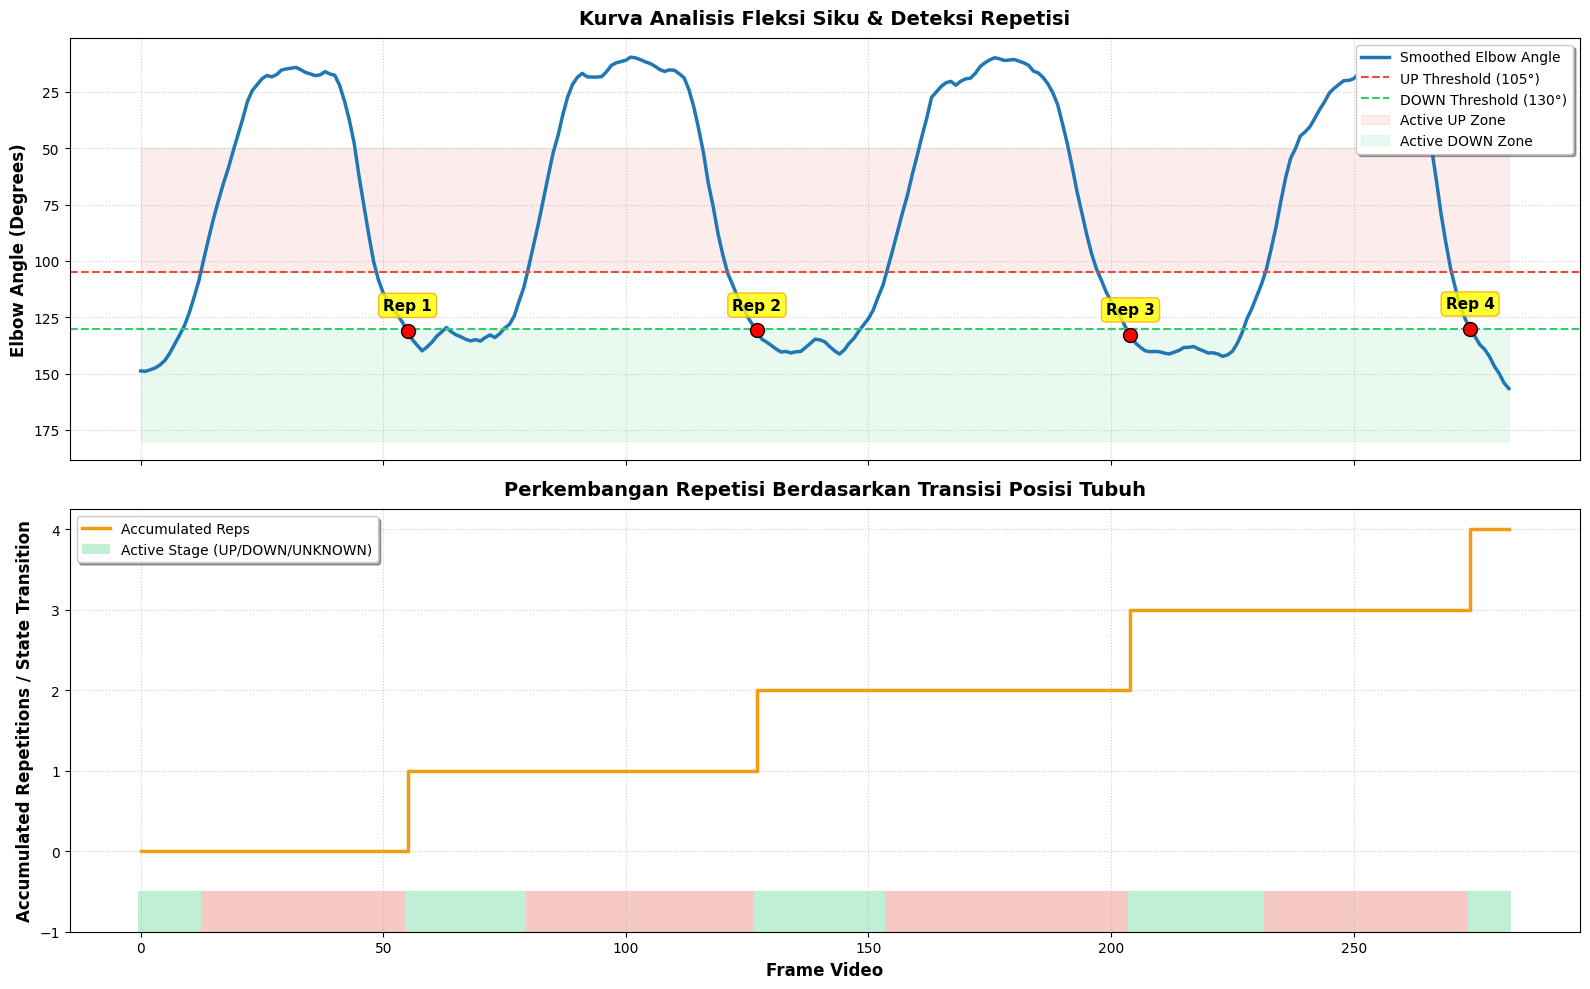

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Konfigurasi Threshold Utama Hasil Tuning
TUNED_DOWN_ANGLE = 130  # Siku melurus (DOWN)
TUNED_UP_ANGLE = 105    # Siku menekuk maksimal (UP)

state = "UNKNOWN"
reps = 0
tuned_counter_data = []

# 2. Jalankan Ulang Logika State Machine menggunakan final_processed_data yang ada di kernel
for data in final_processed_data:
    angle = data["angle"]
    if angle is None:
        tuned_counter_data.append({
            **data,
            "state": state,
            "reps": reps
        })
        continue

    # Deteksi transisi posisi
    if angle <= TUNED_UP_ANGLE:
        if state in ["DOWN", "UNKNOWN"]:
            state = "UP"
    elif angle >= TUNED_DOWN_ANGLE:
        if state == "UP":
            reps += 1
        state = "DOWN"

    tuned_counter_data.append({
        **data,
        "state": state,
        "reps": reps
    })

# 3. Print Ringkasan Evaluasi
print("=" * 55)
print("         LAPORAN EVALUASI GERAKAN PULL-UP            ")
print("=" * 55)
print(f"Batas Atas Deteksi (UP Threshold)   : {TUNED_UP_ANGLE}°")
print(f"Batas Bawah Deteksi (DOWN Threshold): {TUNED_DOWN_ANGLE}°")
print(f"Total Repetisi Terhitung            : {reps} Repetisi")
print("=" * 55)

# 4. Membuat Multi-panel Dashboard Visualisasi
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

# --- Panel 1: Analisis Sudut Siku & Deteksi ---
angles = [d["angle"] if d["angle"] is not None else np.nan for d in tuned_counter_data]
ax1.plot(angles, label="Smoothed Elbow Angle", color='#1f77b4', linewidth=2.5)

# Warnai batas zona gerak
ax1.axhline(TUNED_UP_ANGLE, color='#e74c3c', linestyle="--", linewidth=1.5, label=f"UP Threshold ({TUNED_UP_ANGLE}°)")
ax1.axhline(TUNED_DOWN_ANGLE, color='#2ecc71', linestyle="--", linewidth=1.5, label=f"DOWN Threshold ({TUNED_DOWN_ANGLE}°)")
ax1.fill_between(range(len(angles)), 50, TUNED_UP_ANGLE, color='#e74c3c', alpha=0.1, label="Active UP Zone")
ax1.fill_between(range(len(angles)), TUNED_DOWN_ANGLE, 180, color='#2ecc71', alpha=0.1, label="Active DOWN Zone")

# Berikan penanda bulat (Scatter Plot) dan anotasi teks pada titik kenaikan reps
rep_indices = []
for i in range(1, len(tuned_counter_data)):
    if tuned_counter_data[i]["reps"] > tuned_counter_data[i-1]["reps"]:
        rep_indices.append(i)
        rep_val = tuned_counter_data[i]["reps"]
        ax1.plot(i, angles[i], 'ro', markersize=10, markeredgecolor='black', zorder=5)
        ax1.annotate(f"Rep {rep_val}",
                     (i, angles[i]),
                     textcoords="offset points",
                     xytext=(0,15),
                     ha='center',
                     fontweight='bold',
                     fontsize=11,
                     color='black',
                     bbox=dict(boxstyle="round,pad=0.3", fc="yellow", alpha=0.8, ec="orange"))

ax1.invert_yaxis() # Posisi siku tertekuk (UP/Naik) digambarkan di atas secara fisik
ax1.set_ylabel("Elbow Angle (Degrees)", fontsize=12, fontweight='semibold')
ax1.set_title("Kurva Analisis Fleksi Siku & Deteksi Repetisi", fontsize=14, fontweight='bold', pad=10)
ax1.legend(loc="upper right", frameon=True, shadow=True)
ax1.grid(True, linestyle=':', alpha=0.6)

# --- Panel 2: Transisi State vs Akumulasi Reps ---
states = [d["state"] for d in tuned_counter_data]
state_numeric = [1 if s == "UP" else (0 if s == "DOWN" else -0.5) for s in states]
reps_cumulative = [d["reps"] for d in tuned_counter_data]

# Plot Akumulasi Repetisi (Line Chart Tangga)
ax2.step(range(len(reps_cumulative)), reps_cumulative, where='post', color='#f39c12', linewidth=2.5, label="Accumulated Reps")

# Plot Transisi Status Tubuh (Bar Plot Transparan)
color_map = {'UP': '#e74c3c', 'DOWN': '#2ecc71', 'UNKNOWN': '#95a5a6'}
bar_colors = [color_map[s] for s in states]
ax2.bar(range(len(states)), [0.5 if s != "UNKNOWN" else 0.2 for s in states],
        bottom=-1.0, color=bar_colors, alpha=0.3, width=1.0, label="Active Stage (UP/DOWN/UNKNOWN)")

# Kustomisasi Sumbu
ax2.set_xlabel("Frame Video", fontsize=12, fontweight='semibold')
ax2.set_ylabel("Accumulated Repetitions / State Transition", fontsize=12, fontweight='semibold')
ax2.set_title("Perkembangan Repetisi Berdasarkan Transisi Posisi Tubuh", fontsize=14, fontweight='bold', pad=10)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc="upper left", frameon=True, shadow=True)

plt.tight_layout()
plt.show()